# H15 Part A · Step 1 · The data the side-car learns from

This notebook is the review of **step 1** of the revised plan,
[docs/drivejepa-perception-sidecar-A.md](../../../docs/drivejepa-perception-sidecar-A.md) (§3). It reads
the caches the side-car trains on and shows, on real samples:

1. what one sample is: its window of frames, and the two camera frames the ViT reads;
2. its labels, seen from above;
3. its targets drawn on the image the ViT reads;
4. how each of the 512 tokens becomes a direction in 3D (the rays);
5. the three splits, side by side;
6. the motion labels: velocity and each agent's next second;
7. what the labels cannot tell.

**How to run it.** Use Drive-JEPA's interpreter (`[python] drivejepa` in `gallops.toml`: Python 3.9, numpy,
matplotlib, PIL, pandas). Every location comes from the site config (`gallops.toml`, found at the
repository root); nothing here prints a path. It reads only labels, geometry and images, never a model.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Polygon, Rectangle
from matplotlib.ticker import FuncFormatter

from gallops.config import SiteConfig
from gallops.drivejepa_perception import navsim_data, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
NAVSIM = Path(cfg.resolve("{data.navsim}"))

labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
SPLITS = ("train", "select", "report")
rows = {s: np.flatnonzero(np.isin(token_logs, splits[s])) for s in SPLITS}
proj = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r")))
ego_status = np.asarray(np.load(RUNS / "tokens-v1" / "ego_status.npy", mmap_mode="r"))
print(f"{len(token_logs):,} samples from {len(logs):,} logs")
print({s: f"{len(splits[s]):,} logs, {len(rows[s]):,} samples" for s in SPLITS})


def targets_of(row):
    return tg.build(navsim_data.agents_of(labels, row), proj[row])


def y_axis_left(ax):
    """Bird's-eye axes plot -y to the right, so left is left; the tick labels then show y itself."""
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")


def city_of(log_name):
    import pickle

    with open(NAVSIM / "navsim_logs" / "trainval" / f"{log_name}.pkl", "rb") as fh:
        return log_name, pickle.load(fh)[0]["map_location"]


from concurrent.futures import ProcessPoolExecutor

with ProcessPoolExecutor(32) as pool:  # one pickle per log, about 30 s
    cities = dict(pool.map(city_of, sorted(set(token_logs)), chunksize=4))

103,288 samples from 1,192 logs
{'train': '1,071 logs, 94,195 samples', 'select': '51 logs, 4,457 samples', 'report': '70 logs, 4,636 samples'}


## 1. What one sample is

A **sample** is one navtrain token: the current frame *t* of a window of 14 frames, 4 of history ending
at *t* and 10 of future, 0.5 s apart. The side-car is trained to describe the scene at *t* from the
released ViT's output, which saw CAM_F0 at **t − 0.5 s and t**.

The sample below is drawn from the **select** logs (seeded), among samples with at least four targets
within 30 m, a vehicle and a pedestrian among them, and the ego moving.

In [2]:
rng = np.random.default_rng(3)


def describe(row):
    t = targets_of(row)
    m = t["mask"]
    near = np.hypot(t["box"][m, 0], t["box"][m, 1]) < 30
    speed = float(np.hypot(*ego_status[row, -1, 3:5]))
    return int(near.sum()), set(t["cls"][m][near].tolist()), speed


row = next(
    r
    for r in rng.permutation(rows["select"])
    if (lambda d: d[0] >= 4 and {0, 1} <= d[1] and d[2] > 3.0)(describe(r))
)
token, log = str(labels["token"][row]), str(token_logs[row])
frames = views.window_frames(NAVSIM, log, token)
t0 = frames[navsim_data.CURRENT]["timestamp"]
print("frame times, relative to t (s):", [round((f["timestamp"] - t0) / 1e6, 2) for f in frames])
print("city:", frames[navsim_data.CURRENT]["map_location"], "| ego speed: %.1f m/s" % describe(row)[2])
images = {
    "t − 0.5 s": views.read_image(views.camera_path(NAVSIM, frames[navsim_data.CURRENT - 1])),
    "t": views.read_image(views.camera_path(NAVSIM, frames[navsim_data.CURRENT])),
}
print("full-size image:", images["t"].shape)

frame times, relative to t (s): [-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
city: us-nv-las-vegas-strip | ego speed: 3.4 m/s
full-size image: (1080, 1920, 3)


**The two frames, full size (1920×1080).** The shaded bands are the 28 rows top and bottom that the
vendor crops before resizing (`drive_jepa_features._get_camera_feature`).

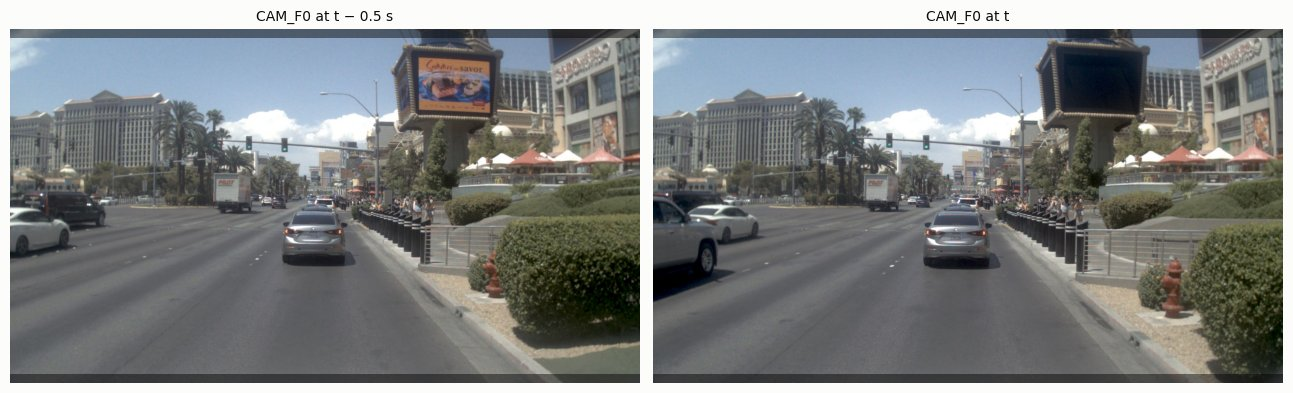

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, (name, image) in zip(axes, images.items()):
    ax.imshow(image)
    for y0 in (0, image.shape[0] - views.CROP_ROWS):
        ax.add_patch(Rectangle((0, y0), image.shape[1], views.CROP_ROWS, color="black", alpha=0.45, lw=0))
    ax.set_title(f"CAM_F0 at {name}")
    ax.axis("off")
plt.tight_layout()
views.show_jpeg(fig)

**What the ViT reads: 512×256, then 16×32 patches of 16×16 pixels.** The crop leaves 1920×1024, and the
resize scales x by 0.267 and y by 0.25, so the picture is squeezed sideways a little (1.875 : 1 into
2 : 1). V-JEPA's tubelet of 2 fuses the two frames, patch by patch, into **one** grid of 512 tokens: motion
is inside each token, there is no separate token per frame.

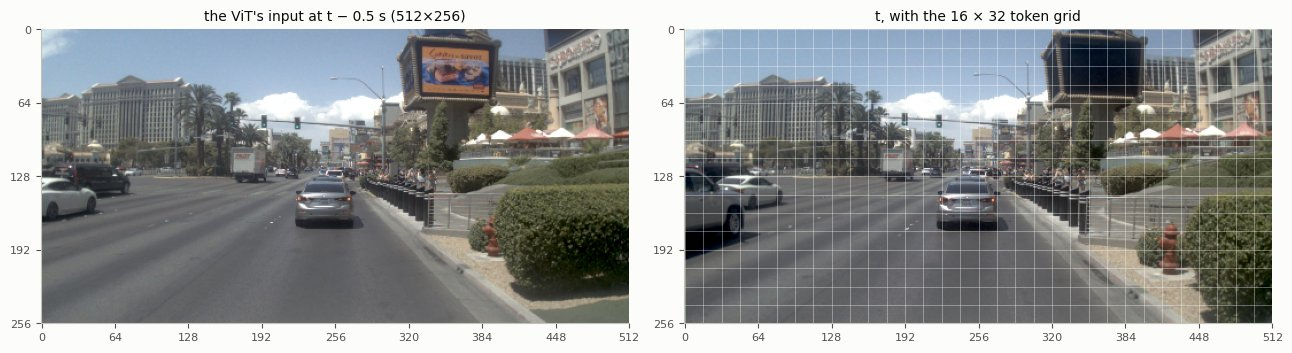

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (name, image) in zip(axes, images.items()):
    ax.imshow(views.model_view(image))
    ax.set_title(f"the ViT's input at {name} (512×256)")
    ax.set_xticks(range(0, 513, 64))
    ax.set_yticks(range(0, 257, 64))
    ax.grid(False)
ax = axes[1]
for x in range(0, 513, views.PATCH):
    ax.axvline(x, color="white", lw=0.4, alpha=0.6)
for y in range(0, 257, views.PATCH):
    ax.axhline(y, color="white", lw=0.4, alpha=0.6)
ax.set_title("t, with the 16 × 32 token grid")
plt.tight_layout()
views.show_jpeg(fig)

## 2. The labels of that sample, from above

Every annotated agent within 60 m at *t*, in *t*'s ego frame: x forward (up), y left (left). The labels
keep all of them; the **targets** are only the ones the side-car is asked for (§3.4 of the plan):
a vehicle, pedestrian or cyclist within 50 m whose centre projects into the image, nearest first, at
most 64.

- coloured outlines: targets, by class, with an arrow for 1 s of their labelled velocity and dots at
  their labelled positions at +0.5 s and +1.0 s;
- grey: agents that are not targets (static objects, or out of the camera's view, or beyond 50 m);
- the wedge: the camera's horizontal view; arcs at 20, 30 and 50 m.

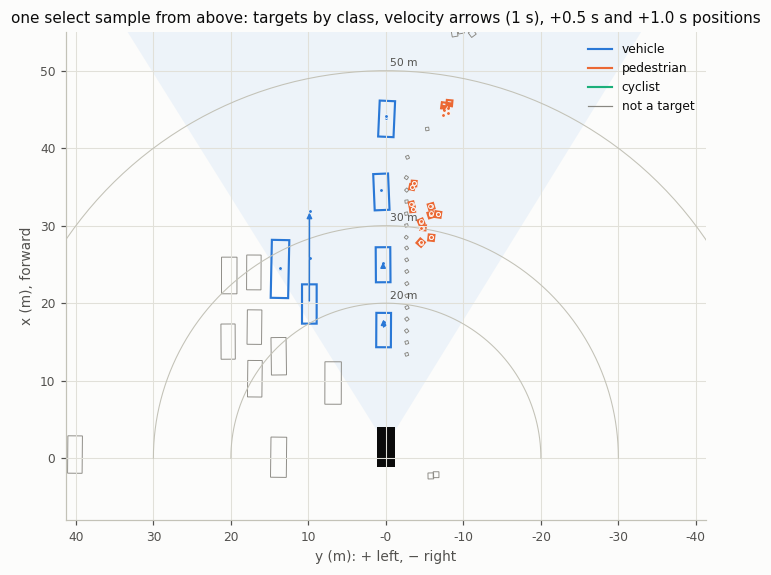

19 targets of 99 labelled agents


,class,x (m),y (m),range (m),l × w × h (m),yaw (°),speed (m/s),"path known (+0.5, +1.0 s)"
0,vehicle,16.53,0.29,16.53,4.4 × 1.9 × 1.5,-0.30,1.77,"(True, True)"
1,vehicle,19.90,9.88,22.21,5.1 × 1.9 × 1.5,-0.03,12.19,"(True, True)"
2,vehicle,24.96,0.36,24.96,4.5 × 1.9 × 1.6,0.38,0.32,"(True, True)"
3,vehicle,24.42,13.66,27.98,7.5 × 2.2 × 2.1,-1.16,0.00,"(True, True)"
4,pedestrian,27.81,-4.49,28.17,0.8 × 0.8 × 1.8,-221.04,0.01,"(True, True)"
5,pedestrian,28.45,-5.86,29.05,0.7 × 0.8 × 1.8,83.64,0.01,"(True, True)"
6,pedestrian,29.75,-4.80,30.14,0.7 × 0.6 × 1.5,83.91,0.15,"(True, True)"
7,pedestrian,30.49,-4.53,30.83,0.7 × 0.7 × 1.7,-247.01,0.01,"(True, True)"
8,pedestrian,31.41,-5.81,31.94,0.7 × 0.7 × 1.9,-72.97,0.04,"(True, True)"
9,pedestrian,31.44,-6.73,32.16,0.7 × 0.7 × 1.9,81.60,0.01,"(True, True)"


In [5]:
EGO = dict(length=5.176, width=2.297, ahead=1.461)  # nuPlan's Pacifica (geometry.py), origin at the rear axle


def bev(ax, row, reach=55.0, show_paths=True):
    agents = navsim_data.agents_of(labels, row)
    t = targets_of(row)
    m = t["mask"]
    target_xy = t["box"][m, :2]
    edges = views.view_edges(proj[row], reach=reach + 10)
    ax.add_patch(Polygon(edges[:, ::-1] * [-1, 1], closed=True, color="#86b6ef", alpha=0.12, lw=0))
    for radius in (20, 30, 50):
        a = np.linspace(-np.pi / 2, np.pi / 2, 100)
        ax.plot(-radius * np.sin(a), radius * np.cos(a), color=views.AXIS, lw=0.7)
        ax.text(0.5, radius + 0.6, f"{radius} m", color=views.INK_2, fontsize=7)
    for k in range(len(agents["cls"])):
        box = agents["box"][k]
        is_target = np.any(np.all(np.isclose(target_xy, box[:2]), axis=1)) and agents["cls"][k] < 3
        if is_target:
            continue
        outline = views.footprint(box[None])[0]
        ax.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, fill=False, ec=views.GREY, lw=0.6))
    for k in np.flatnonzero(m):
        colour = views.CLASS_COLOURS[t["cls"][k]]
        outline = views.footprint(t["box"][k][None])[0]
        ax.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, fill=False, ec=colour, lw=1.4))
        x, y = t["box"][k, :2]
        vx, vy = t["vel"][k]
        if np.hypot(vx, vy) > 0.3:
            ax.annotate("", xy=(-(y + vy), x + vx), xytext=(-y, x),
                        arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.0, mutation_scale=7))
        if show_paths:
            ok = t["path_ok"][k]
            pts = t["box"][k, None, :2] + t["path"][k]
            pts = pts[ok]
            if len(pts):
                ax.plot(-pts[:, 1], pts[:, 0], "o", ms=2.5, color=colour, mec=views.SURFACE, mew=0.6)
    ego = np.array([[EGO["ahead"] + EGO["length"] / 2, EGO["width"] / 2], [EGO["ahead"] + EGO["length"] / 2, -EGO["width"] / 2],
                    [EGO["ahead"] - EGO["length"] / 2, -EGO["width"] / 2], [EGO["ahead"] - EGO["length"] / 2, EGO["width"] / 2]])
    ax.add_patch(Polygon(np.c_[-ego[:, 1], ego[:, 0]], closed=True, color=views.INK, lw=0))
    ax.set_xlim(-reach * 0.75, reach * 0.75)
    ax.set_ylim(-8, reach)
    ax.set_aspect("equal")
    y_axis_left(ax)


fig, ax = plt.subplots(figsize=(7.5, 7))
bev(ax, row)
handles = [plt.Line2D([], [], color=c, lw=1.4, label=n) for n, c in zip(views.CLASS_NAMES, views.CLASS_COLOURS)]
handles.append(plt.Line2D([], [], color=views.GREY, lw=0.8, label="not a target"))
ax.legend(handles=handles, loc="upper right")
ax.set_title("one select sample from above: targets by class, velocity arrows (1 s), +0.5 s and +1.0 s positions")
plt.show()

t = targets_of(row)
m = t["mask"]
table = pd.DataFrame(
    {
        "class": [views.CLASS_NAMES[c] for c in t["cls"][m]],
        "x (m)": t["box"][m, 0],
        "y (m)": t["box"][m, 1],
        "range (m)": np.hypot(t["box"][m, 0], t["box"][m, 1]),
        "l × w × h (m)": [f"{l:.1f} × {w:.1f} × {h:.1f}" for l, w, h in t["box"][m, 3:6]],
        "yaw (°)": np.degrees(t["box"][m, 6]),
        "speed (m/s)": np.hypot(t["vel"][m, 0], t["vel"][m, 1]),
        "path known (+0.5, +1.0 s)": [tuple(bool(v) for v in ok) for ok in t["path_ok"][m]],
    }
)
print(f"{int(m.sum())} targets of {len(navsim_data.agents_of(labels, row)['cls'])} labelled agents")
table.round(2)

## 3. The targets on the image the ViT reads

Each target's 3D box, projected through **the same matrix the side-car's rays come from**
(`targets.front_projection`: the vendor's `lidar2img` for CAM_F0 times `TO_512`). If the projection, the
camera slot or the box convention were wrong, the boxes would not sit on the agents. `views.box_corners`
takes a box's `z` as its **centre** height.

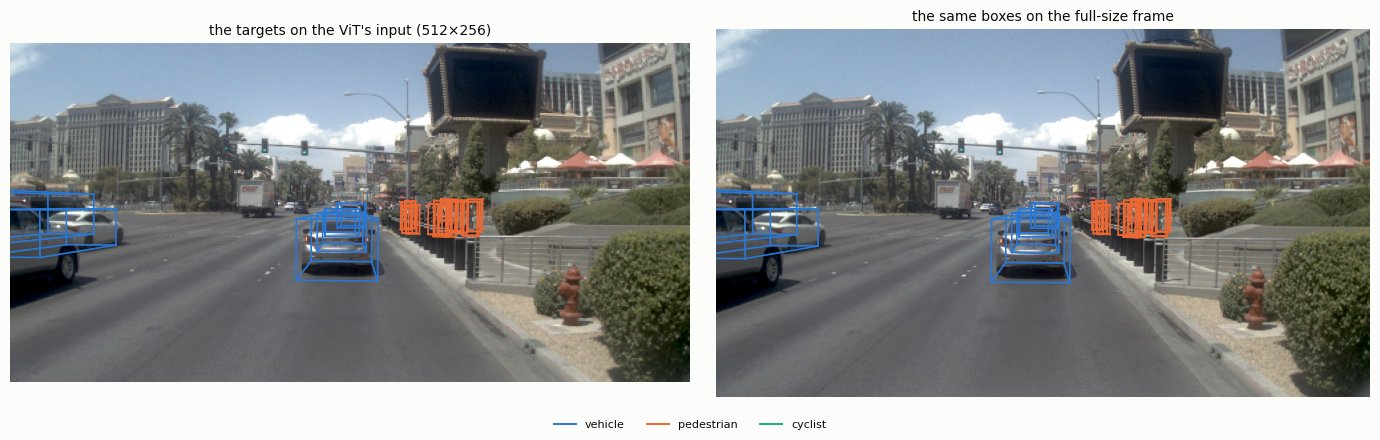

In [6]:
def draw_boxes(ax, row, image, scale=1.0, lw=1.2):
    t = targets_of(row)
    ax.imshow(image)
    p = np.diag([scale, scale, 1.0, 1.0]) @ proj[row]
    for k in np.flatnonzero(t["mask"]):
        for (u0, v0), (u1, v1) in views.box_edges_2d(p, t["box"][k][None])[0]:
            ax.plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[t["cls"][k]], lw=lw)
    ax.set_xlim(0, image.shape[1])
    ax.set_ylim(image.shape[0], 0)
    ax.axis("off")


# The token image is 512×256; the full-size frame is 1920×1080 with 28 rows cropped top and bottom:
# a token-image pixel (u, v) is full-size (u · 1920/512, v · 1024/256 + 28).
TO_FULL = np.array([[1920 / 512, 0, 0, 0], [0, 1024 / 256, 28, 0], [0, 0, 1, 0], [0, 0, 0, 1]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.0, 1.0]})
draw_boxes(axes[0], row, views.model_view(images["t"]))
axes[0].set_title("the targets on the ViT's input (512×256)")
t = targets_of(row)
axes[1].imshow(images["t"])
for k in np.flatnonzero(t["mask"]):
    for (u0, v0), (u1, v1) in views.box_edges_2d(TO_FULL @ proj[row], t["box"][k][None])[0]:
        axes[1].plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[t["cls"][k]], lw=1.2)
axes[1].set_xlim(0, 1920)
axes[1].set_ylim(1080, 0)
axes[1].axis("off")
axes[1].set_title("the same boxes on the full-size frame")
fig.legend(handles=[plt.Line2D([], [], color=c, lw=1.4, label=n) for n, c in zip(views.CLASS_NAMES, views.CLASS_COLOURS)],
           loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.06, 1, 1))
views.show_jpeg(fig)

**Six more samples**, one or two per city, drawn from all three splits (seeded), each with its
targets. Title: split, city, ego speed, number of targets.

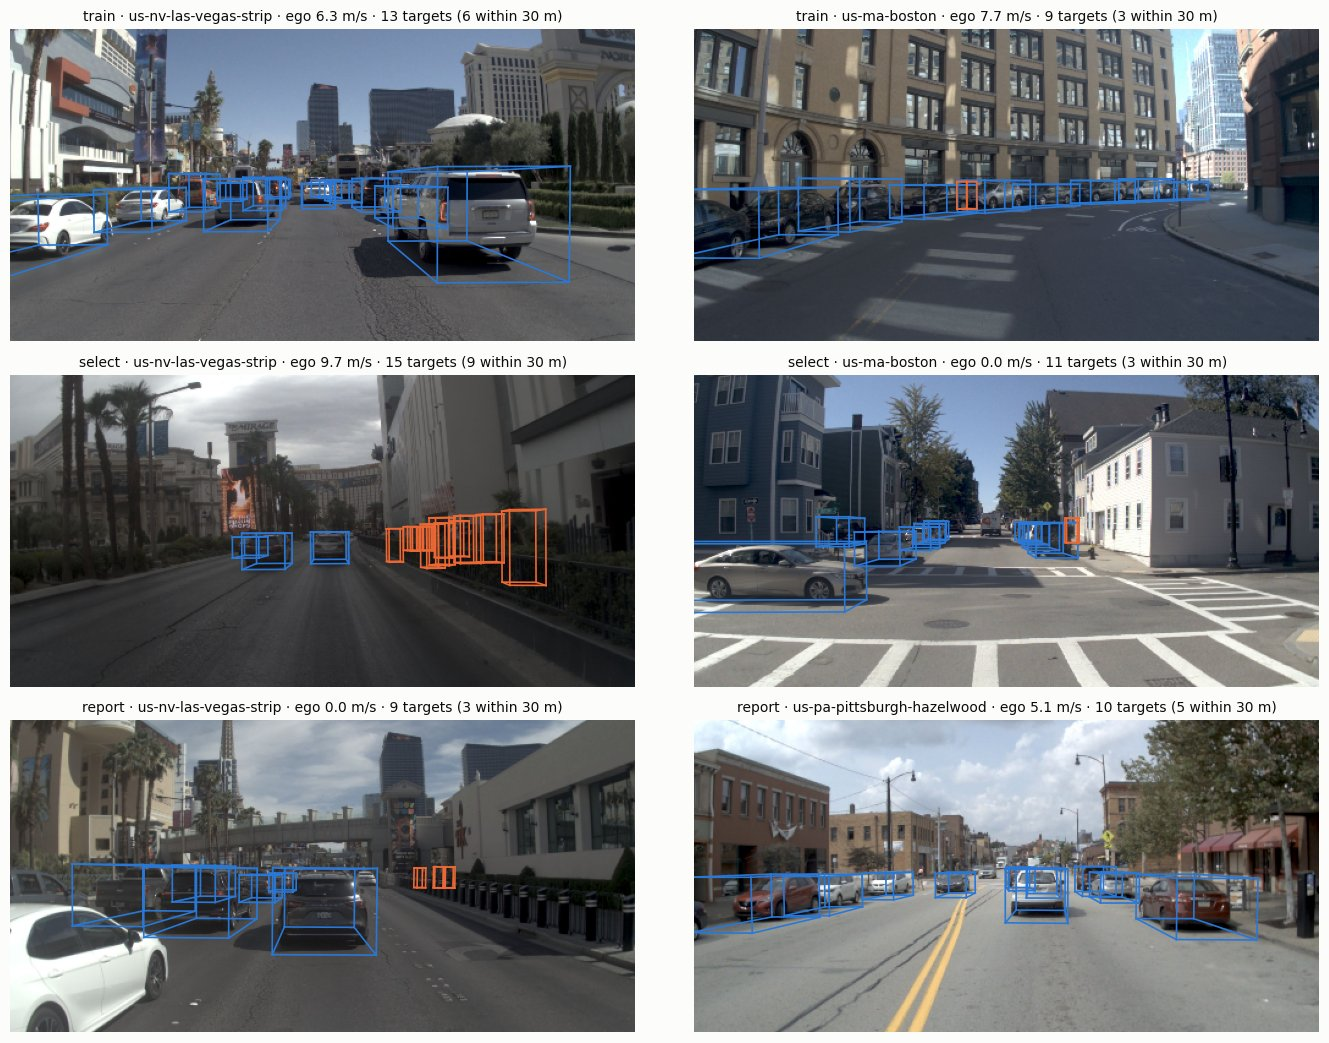

In [7]:
picked = []
for split in SPLITS:
    used = set()
    for r in np.random.default_rng(11).permutation(rows[split]):
        city = cities[token_logs[r]]
        if city in used or describe(r)[0] < 3:
            continue
        picked.append((split, r, city))
        used.add(city)
        if len(used) == 2:
            break
fig, axes = plt.subplots(3, 2, figsize=(14, 10.5))
for ax, (split, r, city) in zip(axes.ravel(), picked):
    frame = views.window_frames(NAVSIM, str(token_logs[r]), str(labels["token"][r]))[navsim_data.CURRENT]
    image = views.read_image(views.camera_path(NAVSIM, frame))
    draw_boxes(ax, r, views.model_view(image))
    n, _, speed = describe(r)
    ax.set_title(f"{split} · {city} · ego {speed:.1f} m/s · {int(targets_of(r)['mask'].sum())} targets ({n} within 30 m)")
plt.tight_layout()
views.show_jpeg(fig)

**What the pictures show.** The boxes sit on the vehicles and pedestrians they label: the projection
(slot 1, `TO_512`), the 28-row crop and the resize are right, and so is reading `z` as the box's
centre height (boxes drawn with `z` as their bottom would float half a box above the road). Agents
hidden behind others are still drawn: they are targets too (§7 measures how often).

## 4. From a token to a direction in 3D: the rays

The side-car knows where each token looks by its **ray**: the camera's centre, and the direction through
the token's pixel centre ((16 c + 8, 16 r + 8) on the 512×256 image), from the inverse of the projection.
`sidecar.ray_pos` places 16 points along each ray, from 1 to 60 m, log-spaced, and an MLP turns their 48
coordinates into the token's position embedding. Below: the rays of the middle token row, every 4th
column, and their 16 points.

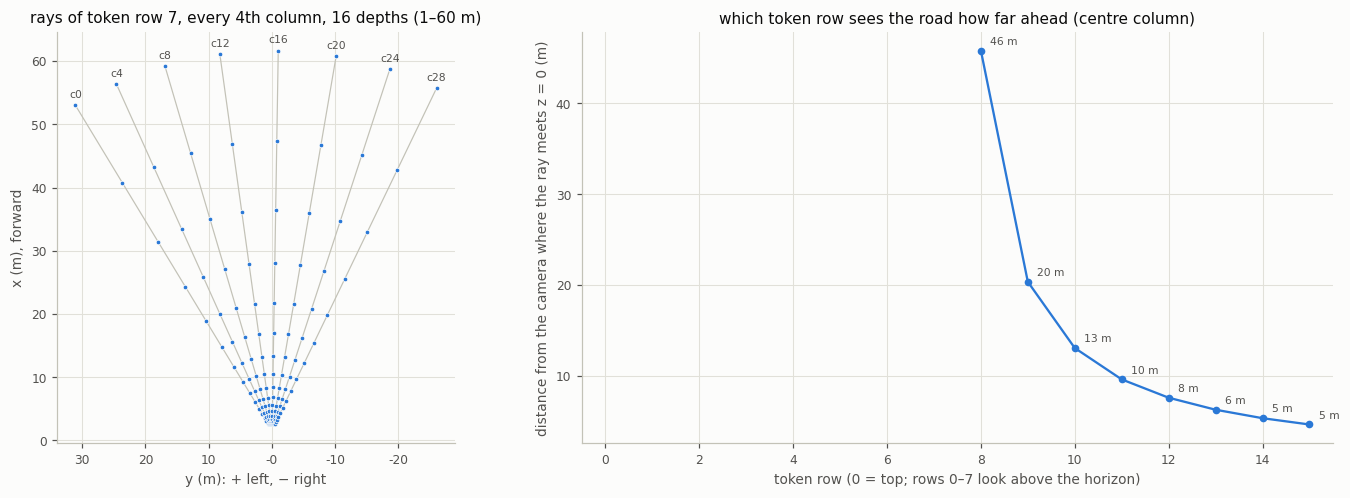

rows above the horizon never meet the ground: [0, 1, 2, 3, 4, 5, 6, 7]


In [8]:
depths = np.logspace(0, np.log10(60.0), 16)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.0, 1.25]})
ax = axes[0]
for col in range(0, 32, 4):
    for r_tok, shade in ((7, views.CLASS_COLOURS[0]),):
        centre, ray = views.camera_ray(proj[row], 16 * col + 8, 16 * r_tok + 8)
        pts = centre + depths[:, None] * ray
        ax.plot(-pts[:, 1], pts[:, 0], "-", color=views.AXIS, lw=0.8)
        ax.plot(-pts[:, 1], pts[:, 0], "o", ms=3, color=shade, mec=views.SURFACE, mew=0.5)
        ax.text(-pts[-1, 1], pts[-1, 0] + 1.2, f"c{col}", ha="center", fontsize=7, color=views.INK_2)
ax.set_aspect("equal")
y_axis_left(ax)
ax.set_title("rays of token row 7, every 4th column, 16 depths (1–60 m)")
ax = axes[1]
heights = []
for r_tok in range(16):
    centre, ray = views.camera_ray(proj[row], 16 * 15 + 8, 16 * r_tok + 8)
    # where the ray meets the ground (z = 0), if it points down
    heights.append(-centre[2] / ray[2] * np.hypot(ray[0], ray[1]) if ray[2] < 0 else np.nan)
ax.plot(range(16), heights, "o-", color=views.CLASS_COLOURS[0], ms=4)
for r_tok, h in enumerate(heights):
    if np.isfinite(h):
        ax.annotate(f"{h:.0f} m", (r_tok, h), textcoords="offset points", xytext=(6, 4), fontsize=7, color=views.INK_2)
ax.set_xlim(-0.5, 15.5)
ax.set_xlabel("token row (0 = top; rows 0–7 look above the horizon)")
ax.set_ylabel("distance from the camera where the ray meets z = 0 (m)")
ax.set_title("which token row sees the road how far ahead (centre column)")
plt.tight_layout()
plt.show()
print("rows above the horizon never meet the ground:", [r for r, h in enumerate(heights) if not np.isfinite(h)])

The top half of the grid (rows 0–7) looks above the horizon. On the road, the bottom rows see a few
metres ahead, and **everything beyond about 20 m falls in rows 8 and 9** (row 9's centre meets the road
at 20 m, row 8's at 46 m): an agent's distance beyond 20 m rests on where, within one or two token rows,
its base meets the road, and on its apparent size. That is why depth far out is hard from a 16 × 32 grid, and why the readout reports range bins
rather than one number.

## 5. The three splits

Splits are by **log** (a log's samples are 0.5 s apart and nearly the same), committed in
`recipes/drivejepa_perception/splits.json`, re-drawn from their rule by every run.

In [9]:
per_target, per_sample = [], []
for split in SPLITS:
    for r in rows[split]:
        t = targets_of(r)
        m = t["mask"]
        n = int(m.sum())
        speed = float(np.hypot(*ego_status[r, -1, 3:5]))
        per_sample.append((split, r, n, speed, cities[token_logs[r]], int((labels["count"][r]))))
        if n:
            box, vel = t["box"][m], t["vel"][m]
            ok = t["path_ok"][m]
            at_1s = box[:, :2] + t["path"][m][:, 1]
            cv_err = np.where(ok[:, 1], np.hypot(*(at_1s - (box[:, :2] + vel)).T), np.nan)
            per_target.append(
                pd.DataFrame(
                    {
                        "split": split,
                        "row": r,
                        "cls": t["cls"][m],
                        "range": np.hypot(box[:, 0], box[:, 1]),
                        "speed": np.hypot(vel[:, 0], vel[:, 1]),
                        "ok05": ok[:, 0],
                        "ok10": ok[:, 1],
                        "disp1s": np.where(ok[:, 1], np.hypot(*t["path"][m][:, 1].T), np.nan),
                        "cv_err1s": cv_err,
                        "vx": vel[:, 0],
                        "vy": vel[:, 1],
                    }
                )
            )
targets_df = pd.concat(per_target, ignore_index=True)
samples_df = pd.DataFrame(per_sample, columns=["split", "row", "targets", "ego_speed", "city", "labelled"])
print(f"{len(targets_df):,} targets in {len(samples_df):,} samples")


def summary(split):
    s, t = samples_df[samples_df.split == split], targets_df[targets_df.split == split]
    shares = t.cls.value_counts(normalize=True).reindex(range(3), fill_value=0)
    bins = pd.cut(t.range, [0, 20, 30, 50], right=False).value_counts(normalize=True, sort=False)
    return {
        "logs": len(splits[split]),
        "samples": len(s),
        "targets": len(t),
        "targets / sample (mean)": s.targets.mean(),
        "targets / sample (median)": s.targets.median(),
        "targets / sample (p99)": s.targets.quantile(0.99),
        "samples with no target": (s.targets == 0).mean(),
        "vehicle share": shares[0],
        "pedestrian share": shares[1],
        "cyclist share": shares[2],
        "range 0–20 m": bins.iloc[0],
        "range 20–30 m": bins.iloc[1],
        "range 30–50 m": bins.iloc[2],
        "targets within 30 m": int((t.range < 30).sum()),
        "moving (> 1 m/s)": (t.speed > 1).mean(),
        "ego stopped (< 0.5 m/s)": (s.ego_speed < 0.5).mean(),
    }


pd.DataFrame({s: summary(s) for s in SPLITS})

717,314 targets in 103,288 samples


,train,select,report
logs,1071.000,51.000,70.000
samples,94195.000,4457.000,4636.000
targets,660723.000,32375.000,24216.000
targets / sample (mean),7.014,7.264,5.223
targets / sample (median),5.000,5.000,4.000
targets / sample (p99),42.000,39.000,29.000
samples with no target,0.145,0.159,0.182
vehicle share,0.564,0.553,0.647
pedestrian share,0.430,0.440,0.346
cyclist share,0.005,0.007,0.007


**Cities, by logs and by samples.**

In [10]:
city_logs = pd.DataFrame(
    {s: pd.Series([cities[l] for l in splits[s]]).value_counts() for s in SPLITS}
).fillna(0).astype(int)
city_samples = samples_df.groupby(["city", "split"]).size().unstack().reindex(columns=list(SPLITS)).fillna(0).astype(int)
pd.concat({"logs": city_logs, "samples": city_samples}, axis=1)

logs               samples              
                           train select report   train select report
us-nv-las-vegas-strip        674     33     40   62351   2958   2374
us-ma-boston                 206      9     14   11882    583    489
us-pa-pittsburgh-hazelwood   105      7      8    9568    526    727
sg-one-north                  86      2      8   10394    390   1046

**Targets per sample, class shares and ranges, per split.**

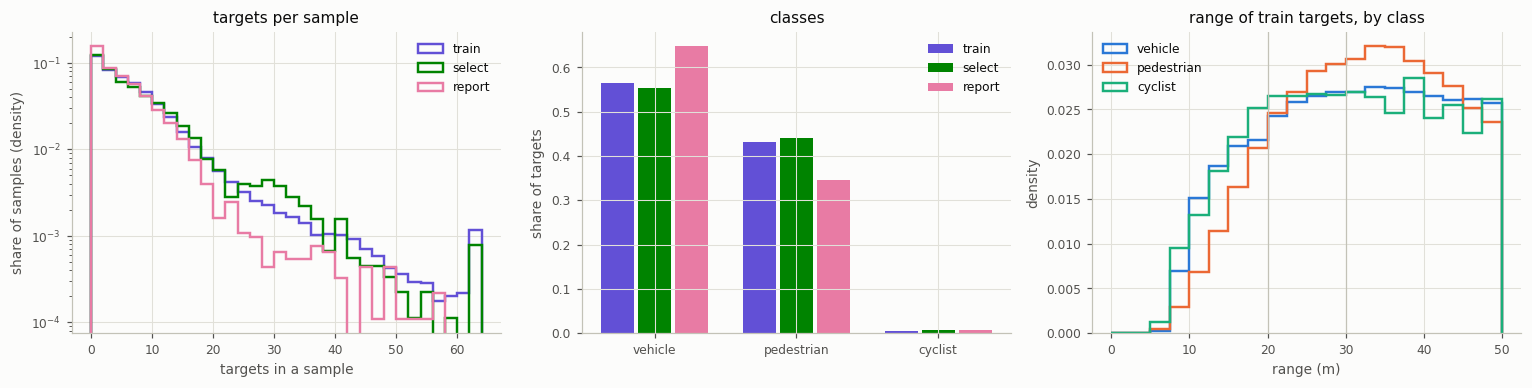

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ax = axes[0]
edges = np.arange(0, 66, 2)
for split in SPLITS:
    n = samples_df[samples_df.split == split].targets
    ax.hist(n, bins=edges, histtype="step", density=True, lw=1.6, color=views.SPLIT_COLOURS[split], label=split)
ax.set_xlabel("targets in a sample")
ax.set_ylabel("share of samples (density)")
ax.set_yscale("log")
ax.legend()
ax.set_title("targets per sample")
ax = axes[1]
width = 0.26
for i, split in enumerate(SPLITS):
    shares = targets_df[targets_df.split == split].cls.value_counts(normalize=True).reindex(range(3), fill_value=0)
    ax.bar(np.arange(3) + (i - 1) * width, shares.values, width=width * 0.9, color=views.SPLIT_COLOURS[split], label=split)
ax.set_xticks(range(3))
ax.set_xticklabels(views.CLASS_NAMES)
ax.set_ylabel("share of targets")
ax.legend()
ax.set_title("classes")
ax = axes[2]
edges = np.arange(0, 51, 2.5)
for c in range(3):
    r = targets_df[(targets_df.split == "train") & (targets_df.cls == c)].range
    ax.hist(r, bins=edges, histtype="step", density=True, lw=1.6, color=views.CLASS_COLOURS[c], label=views.CLASS_NAMES[c])
for x in (20, 30):
    ax.axvline(x, color=views.AXIS, lw=0.8)
ax.set_xlabel("range (m)")
ax.set_ylabel("density")
ax.legend()
ax.set_title("range of train targets, by class")
plt.tight_layout()
plt.show()

**What this changes in the plan** (§3.4):
- more than half of the targets are beyond 30 m; the headline reads the nearer 41–45%;
- the **report** logs have fewer targets per sample and fewer pedestrians than **select**, so all-class
  numbers are never compared across the two, only per class;
- cyclists are about half a percent of targets: their numbers decide nothing;
- the 64-target cap almost never binds.

## 6. The motion labels

**Velocity** is each agent's ground velocity, in the ego's axes (`gt_velocity_3d` at *t*); **the path** is
its labelled centre at +0.5 s and +1.0 s, from the same track one and two frames later. The side-car
predicts both. Below, for train targets: how fast agents move, how far they go in a second, and how well
the label's own velocity predicts the label's own path (constant velocity from the true centre: the
best a kinematic guess can do).

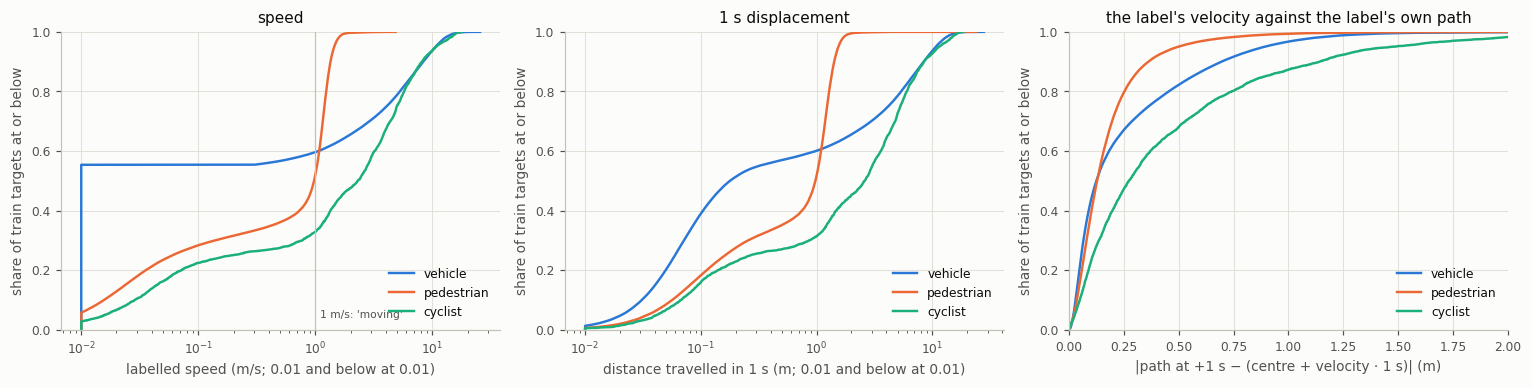

,vehicle,pedestrian,cyclist
moving share,0.404,0.481,0.672
"1 s displacement, median (m)",0.179,0.976,2.604
"1 s displacement, p90 (m)",8.419,1.418,8.458
"constant-velocity error at 1 s, median (m)",0.125,0.128,0.273
"constant-velocity error at 1 s, p90 (m)",0.695,0.361,1.143
path known at +0.5 s,0.992,0.980,0.919
path known at +1.0 s,0.985,0.963,0.867


In [12]:
train_t = targets_df[targets_df.split == "train"]


def cdf(ax, values, colour, label):
    v = np.sort(np.asarray(values, dtype=float))
    v = v[np.isfinite(v)]
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=colour, lw=1.6, label=label)


fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for c in range(3):
    g = train_t[train_t.cls == c]
    cdf(axes[0], np.maximum(g.speed, 0.01), views.CLASS_COLOURS[c], views.CLASS_NAMES[c])
    cdf(axes[1], np.maximum(g.disp1s, 0.01), views.CLASS_COLOURS[c], views.CLASS_NAMES[c])
    cdf(axes[2], g.cv_err1s, views.CLASS_COLOURS[c], views.CLASS_NAMES[c])
axes[0].axvline(1.0, color=views.AXIS, lw=0.8)
axes[0].text(1.1, 0.04, "1 m/s: 'moving'", color=views.INK_2, fontsize=7)
for ax, xlabel, title in (
    (axes[0], "labelled speed (m/s; 0.01 and below at 0.01)", "speed"),
    (axes[1], "distance travelled in 1 s (m; 0.01 and below at 0.01)", "1 s displacement"),
):
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
axes[2].set_xlim(0, 2)
axes[2].set_xlabel("|path at +1 s − (centre + velocity · 1 s)| (m)")
axes[2].set_title("the label's velocity against the label's own path")
for ax in axes:
    ax.set_ylabel("share of train targets at or below")
    ax.set_ylim(0, 1)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        views.CLASS_NAMES[c]: {
            "moving share": (g.speed > 1).mean(),
            "1 s displacement, median (m)": g.disp1s.median(),
            "1 s displacement, p90 (m)": g.disp1s.quantile(0.9),
            "constant-velocity error at 1 s, median (m)": g.cv_err1s.median(),
            "constant-velocity error at 1 s, p90 (m)": g.cv_err1s.quantile(0.9),
            "path known at +0.5 s": g.ok05.mean(),
            "path known at +1.0 s": g.ok10.mean(),
        }
        for c, g in train_t.groupby("cls")
    }
)

**Why the ego's own motion matters.** The velocity label is the agent's ground velocity, but the two
frames show its motion *relative to the camera*, which moves with the ego. A parked car (ground speed
about 0) moves across the image at the ego's own speed. Below, train targets labelled almost still
(under 0.2 m/s): their speed relative to the ego against the ego's speed. They sit on the diagonal: to
report "0 m/s" for them, the side-car has to work out the ego's motion from the image pair alone, since
ego speed is not one of its inputs (an open question for the owner, plan §11 Q3).

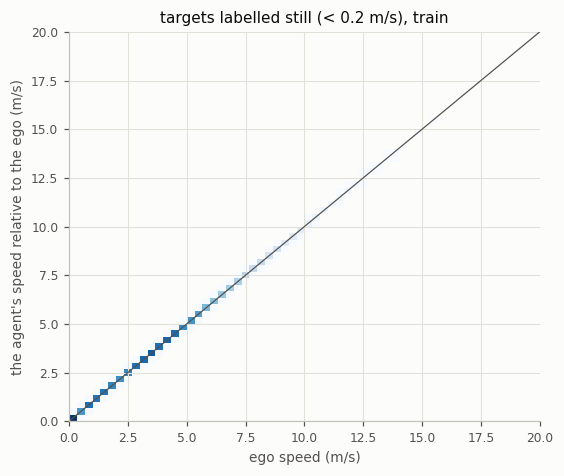

44.9% of train targets are labelled still


In [13]:
still = train_t[train_t.speed < 0.2].sample(20000, random_state=0)
ego_v = ego_status[still.row.values, -1, 3:5]
relative = np.hypot(still.vx.values - ego_v[:, 0], still.vy.values - ego_v[:, 1])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.hist2d(np.hypot(ego_v[:, 0], ego_v[:, 1]), relative, bins=60, range=[[0, 20], [0, 20]], cmap="Blues", cmin=1)
ax.plot([0, 20], [0, 20], color=views.INK_2, lw=0.8)
ax.set_xlabel("ego speed (m/s)")
ax.set_ylabel("the agent's speed relative to the ego (m/s)")
ax.set_title("targets labelled still (< 0.2 m/s), train")
plt.tight_layout()
plt.show()
print(f"{(train_t.speed < 0.2).mean():.1%} of train targets are labelled still")

## 7. What the labels cannot tell

**Occlusion.** OpenScene's annotations carry no visibility flag and no lidar-point count (their keys,
printed below). A target can be hidden behind another and still be a target. A rough measure: the share
of targets whose box on the image is at least 90% covered by the boxes of **nearer targets**. It errs both
ways: it ignores everything that is not a target (buildings, static objects, agents out of range), which
hides more; and it compares rectangles, not silhouettes, which overstates cover (a pedestrian behind a
car's rectangle may show above the bonnet). Read it as the order of magnitude, by range. Measured on the
select and report logs at quarter resolution.

In [14]:
print("annotation keys:", sorted(frames[navsim_data.CURRENT]["anns"].keys()))


def covered_share(row, grid=4):
    """Per target (nearest first): the share of its image box under nearer targets' boxes."""
    t = targets_of(row)
    m = np.flatnonzero(t["mask"])
    out = []
    painted = np.zeros((256 // grid, 512 // grid), bool)
    for k in m:  # targets.build sorts nearest first
        uv, depth = views.project(proj[row], views.box_corners(t["box"][k][None])[0])
        uv = uv[depth > 0.5]
        if len(uv) < 2:
            out.append(np.nan)
            continue
        u0, v0 = np.clip(np.floor(uv.min(0) / grid), 0, [512 // grid - 1, 256 // grid - 1]).astype(int)
        u1, v1 = np.clip(np.ceil(uv.max(0) / grid), 0, [512 // grid, 256 // grid]).astype(int)
        cell = painted[v0:max(v1, v0 + 1), u0:max(u1, u0 + 1)]
        out.append(float(cell.mean()) if cell.size else np.nan)
        painted[v0:max(v1, v0 + 1), u0:max(u1, u0 + 1)] = True
    return out


cover = []
for split in ("select", "report"):
    for r in rows[split]:
        cover += [(split, c) for c in covered_share(r)]
cover = pd.DataFrame(cover, columns=["split", "covered"])
sel_rep = targets_df[targets_df.split.isin(["select", "report"])].reset_index(drop=True)
sel_rep["covered"] = cover.covered.values
sel_rep["range bin"] = pd.cut(sel_rep.range, [0, 20, 30, 50], right=False)
hidden = (
    sel_rep.assign(hidden=sel_rep.covered >= 0.9)
    .groupby(["split", "range bin"]).hidden.mean().unstack()
)
hidden.columns = [str(c) for c in hidden.columns]
hidden

annotation keys: ['gt_boxes', 'gt_names', 'gt_velocity_3d', 'instance_tokens', 'track_tokens']


,"[0, 20)","[20, 30)","[30, 50)"
split,,,
report,0.060,0.192,0.296
select,0.106,0.261,0.384


**"Seen" is decided by the centre alone.** Agents of the three classes within 50 m whose centre is outside
the image but whose box has a corner inside it are neither targets nor ignored by the readout: a detection
of one counts as a false alarm. The white car in the bottom-left corner of the report sample from Las
Vegas, in section 3, is one. How many there are, per sample, against the targets:

In [15]:
partly = []
for split in ("select", "report"):
    for r in rows[split]:
        a = navsim_data.agents_of(labels, r)
        box = a["box"].astype(np.float64)
        near = (a["cls"] < 3) & (np.hypot(box[:, 0], box[:, 1]) <= tg.RANGE_M)
        if not near.any():
            partly.append((split, 0))
            continue
        centre_in = tg.seen(proj[r], box[near, :3])
        uv, depth = views.project(proj[r], views.box_corners(box[near]))
        corner_in = ((depth > 0) & (uv[..., 0] >= 0) & (uv[..., 0] < 512) & (uv[..., 1] >= 0) & (uv[..., 1] < 256)).any(1)
        partly.append((split, int((corner_in & ~centre_in).sum())))
partly = pd.DataFrame(partly, columns=["split", "partly_in_view"])
pd.DataFrame(
    {
        s: {
            "partly in view, not targets, per sample": partly[partly.split == s].partly_in_view.mean(),
            "targets per sample": samples_df[samples_df.split == s].targets.mean(),
        }
        for s in ("select", "report")
    }
)

,select,report
"partly in view, not targets, per sample",0.631,0.481
targets per sample,7.264,5.223


**Box size along a track.** NAVSIM's boxes are machine-made; the labels pass recorded, for every joined
path step, how much the box's largest dimension changed between *t* and the later frame.

In [16]:
size_change = labels["size_change"][np.isin(labels["cls"], [0, 1, 2])]
finite = size_change[np.isfinite(size_change)]
print(f"joined steps: {finite.size:,}; size change > 0.5 m: {(finite > 0.5).mean():.2%}; > 0.2 m: {(finite > 0.2).mean():.2%}")

joined steps: 6,420,801; size change > 0.5 m: 0.43%; > 0.2 m: 3.87%


## Summary for the review

The numbers above are the ones §3 of the plan quotes (*counted* on this site's caches). What they imply:

1. **The inputs are right**: boxes projected through the side-car's own matrix sit on the agents they
   label, at every split and city shown.
2. **The headline (within 30 m) covers under half of the targets**; the 30–50 m bin is reported beside it,
   and depth there rests on one or two token rows.
3. **Report is easier than select** (fewer targets, fewer pedestrians): compare per class, never all-class
   across splits.
4. **Velocity is ground velocity**; for still agents the image shows the ego's motion instead. Whether to
   give the side-car the ego's speed is the owner's call (plan §11 Q3).
5. **Recall cannot reach 1**: many targets beyond 30 m are largely covered by nearer ones (the rough
   measure above), and the labels cannot say which are visible. Agents partly in view but with their
   centre outside are not targets, and detecting them costs precision.
6. **Depth beyond 20 m rests on one or two token rows** (section 4).